# Reproducibility & FAIR Analysis
### PMC FAIR Study 2011–2025

This notebook examines the relationship between **computational reproducibility**
and **FAIR data sharing** — two concepts that are frequently conflated but are
analytically distinct.

## Conceptual framework

Drawing on the framing of Sila et al. (2025) *International Journal of Geographical
Information Science* (doi:10.1080/13658816.2025.2603586) and the broader reproducibility
literature, we distinguish:

| Concept | Definition | Key requirement |
|---------|-----------|----------------|
| **Replicability** | Same team, same methods → same result | Internal consistency |
| **Reproducibility** | Different team, same data+methods → same result | Open data + open code |
| **Reusability** | Different team, new context → new result | FAIR data + documentation |
| **Generalisability** | Findings hold across contexts | Broad sharing + metadata |

**FAIR is necessary but not sufficient for reproducibility.** A dataset can be
Findable, Accessible, Interoperable, and Reusable (FAIR) without being
reproducible — e.g. data without code, or code without environment specifications.
Conversely, a reproducible workflow with private data is not FAIR.

## Reproducibility signals detected in this study

We look for six distinct layers of computational reproducibility evidence in DAS text,
supplementary materials, and article metadata:

| Layer | Signal | Examples |
|-------|--------|---------|
| **R1 Code sharing** | Code in DAS or supplementary | GitHub, GitLab, Code Ocean, Zenodo .ipynb |
| **R2 Workflow management** | Formal pipeline tools | Snakemake, Nextflow, CWL, WDL, nf-core |
| **R3 Environment specification** | Reproducible environments | Docker, Singularity, Conda, requirements.txt |
| **R4 Version pinning** | Specific software versions cited | "R 4.2.1", "Python 3.9", software DOI |
| **R5 Interactive notebooks** | Narrated executable code | Jupyter, R Markdown, Observable |
| **R6 Pre-registration / OSF** | Study pre-registration | OSF, AsPredicted, ClinicalTrials.gov |

## Section map
| § | Topic |
|---|-------|
| 0 | Setup & data loading |
| 1 | Reproducibility signal prevalence over time |
| 2 | Reproducibility × data-sharing score — are they correlated? |
| 3 | Pre/post FAIR: did reproducibility improve after 2016? |
| 4 | Reproducibility score: composite R1-R6 index |
| 5 | Code sharing depth: notebook vs script vs workflow manager |
| 6 | Environment reproducibility: containers + version pinning |
| 7 | Reproducibility vs reusability gap analysis |
| 8 | Pre-registration and study registration signals |
| 9 | Discipline-level reproducibility profiles *(Stage 6)* |
| 10 | Funder × reproducibility compliance *(Stage 6)* |
| 11 | Reproducibility-FAIR quadrant analysis |
| 12 | Statistical summary + exports |


In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


---
## §0 — Setup & Data Loading

In [2]:
import sqlite3, re, warnings
import matplotlib; import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.15)
FIG_W, FIG_H = 14, 5

FAIR_YEAR    = 2016
MANDATE_YEAR = 2019

# ── Colours ──────────────────────────────────────────────────────────────
C_CODE   = '#2ca02c'   # code sharing
C_WF     = '#1f77b4'   # workflow
C_ENV    = '#ff7f0e'   # environment
C_VER    = '#9467bd'   # versioning
C_NB     = '#f28e2b'   # notebooks
C_PREREG = '#e15759'   # pre-registration
C_FAIR   = '#17becf'   # FAIR positive
C_PRE    = '#4e79a7'
C_POST   = '#d62728'

# ── Reproducibility signal patterns ──────────────────────────────────────

# R1: Code sharing (any executable code deposited)
R1_CODE_RE = re.compile(
    r'github\.com|gitlab\.com|bitbucket\.org|codeocean\.com'
    r'|code\s+ocean|sourceforge\.net|zenodo\.org.*(?:code|script|notebook)'
    r'|script[s]?\s+(?:are\s+)?(?:available|deposited|provided)'
    r'|analysis\s+code|custom\s+(?:code|script|software)'
    r'|source\s+code|computational\s+code', re.I)

# R2: Workflow management systems
R2_WF_RE = re.compile(
    r'\bsnakemake\b|\bnextflow\b|\bcwl\b|\bwdl\b|\bnf-core\b'
    r'|\bworkflow\s+management|\bpipeline\s+(?:code|software|tool)'
    r'|\bgalaxy\s+workflow|\bknime\b|\bcomputational\s+workflow'
    r'|\bcromwell\b|\btoil\b|\bmake\s+(?:file|pipeline)', re.I)

# R3: Execution environment specification
R3_ENV_RE = re.compile(
    r'\bdocker\b|\bsingularity\b|\bconda\b|\bbioconda\b'
    r'|\brequirements\.txt\b|\benvironment\.yml\b'
    r'|\bvirtualenv\b|\bpipenv\b|\bpoetry\b'
    r'|\bcontainer(?:ised|ized)?\b|\bdocker(?:file|hub)\b'
    r'|\bapptainer\b|\bpodman\b', re.I)

# R4: Software version pinning
R4_VER_RE = re.compile(
    r'R\s+version\s+\d|\bpython\s+\d\.\d|\bpandas\s+\d'
    r'|\bsoftware\s+version|\bpackage\s+version'
    r'|\bsoftware\s+doi|RRID:SCR_\d'
    r'|\bversion\s+\d+\.\d+\.\d+\b', re.I)

# R5: Interactive / narrated notebooks
R5_NB_RE = re.compile(
    r'jupyter|\.ipynb\b|r\s+markdown|\.rmd\b|rmarkdown'
    r'|observable\s+notebook|quarto\s+(?:document|notebook)'
    r'|pluto\.jl|\bnotebook\s+(?:code|file|available)', re.I)

# R6: Pre-registration / study registration
R6_PREREG_RE = re.compile(
    r'pre.?(?:register|registr)|osf\.io(?:/[a-z0-9]+)?'
    r'|aspredicted\.org|clinicaltrials\.gov'
    r'|anzctr\.org|isrctn\b|prospero\b'
    r'|registered\s+(?:before|prior\s+to)\s+data\s+collect'
    r'|open\s+science\s+framework', re.I)

DB_PATH = Path('../data/processed/pmc_fair.db')
assert DB_PATH.exists(), f'Database not found: {DB_PATH}'

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")
con = sqlite3.connect(DB_PATH)

def qdb(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

tables = {r[0] for r in con.execute(
    'SELECT name FROM sqlite_master WHERE type="table"').fetchall()}

HAS_SUPP   = 'supplementary_material' in tables
HAS_FUNDER = 'article_funder'         in tables
HAS_DISC   = 'article_discipline'     in tables
HAS_RC     = 'repo_classification'    in tables

for lbl, flag in [
        ('supplementary_material ', HAS_SUPP),
        ('article_funder (Stage 6)', HAS_FUNDER),
        ('article_discipline     ', HAS_DISC),
        ('repo_classification    ', HAS_RC)]:
    print(f'  {"OK" if flag else "--"}  {lbl}')

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"


  OK  supplementary_material 
  OK  article_funder (Stage 6)
  OK  article_discipline     
  OK  repo_classification    


### Build reproducibility signals on master frame

In [3]:
df = qdb("""
    SELECT
        a.article_id,
        a.year      AS year,
        a.journal_id,
        COALESCE(da.statement, '')   AS das_text,
        COALESCE(da.source, '')      AS das_source,
        dc.data_sharing_score,
        dc.primary_category          AS das_cat,
        dc.mentions_license,
        dc.mentions_doi,
        dc.mentions_github,
        dc.has_url,
        dc.has_accession,
        dc.word_count                AS das_words
    FROM article a
    JOIN das_category dc     ON dc.article_id = a.article_id
    LEFT JOIN data_availability da ON da.article_id = a.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")

# Apply all 6 reproducibility signal detectors
df['r1_code']   = df['das_text'].apply(lambda t: bool(R1_CODE_RE.search(str(t))))
df['r2_wf']     = df['das_text'].apply(lambda t: bool(R2_WF_RE.search(str(t))))
df['r3_env']    = df['das_text'].apply(lambda t: bool(R3_ENV_RE.search(str(t))))
df['r4_ver']    = df['das_text'].apply(lambda t: bool(R4_VER_RE.search(str(t))))
df['r5_nb']     = df['das_text'].apply(lambda t: bool(R5_NB_RE.search(str(t))))
df['r6_prereg'] = df['das_text'].apply(lambda t: bool(R6_PREREG_RE.search(str(t))))

# Composite reproducibility score (0-6, one point per layer)
REPRO_COLS = ['r1_code','r2_wf','r3_env','r4_ver','r5_nb','r6_prereg']
df['repro_score'] = df[REPRO_COLS].sum(axis=1)

# Any reproducibility signal (R1 or above)
df['has_repro'] = df['repro_score'] >= 1

# High reproducibility (3+ layers: code + workflow/env + version/notebook)
df['high_repro'] = df['repro_score'] >= 3

# Era label
ERA_ORDER = ['Pre-mandate (2011-15)','FAIR era (2016-18)',
             'Mandate era (2019-22)','Strong mandate (2023-25)']
def era_label(y):
    if y <= 2015: return ERA_ORDER[0]
    if y <= 2018: return ERA_ORDER[1]
    if y <= 2022: return ERA_ORDER[2]
    return ERA_ORDER[3]
df['era'] = df['year'].apply(era_label)
df['has_das'] = df['das_source'].str.strip().ne('')

n = len(df)
print(f'Master frame: {n:,} articles')
print()
for col, lbl, clr in [
        ('r1_code',   'R1: Code sharing     ', C_CODE),
        ('r2_wf',     'R2: Workflow manager ', C_WF),
        ('r3_env',    'R3: Environment spec ', C_ENV),
        ('r4_ver',    'R4: Version pinning  ', C_VER),
        ('r5_nb',     'R5: Interactive NB   ', C_NB),
        ('r6_prereg', 'R6: Pre-registration ', C_PREREG)]:
    cnt = df[col].sum()
    print(f'  {lbl} {cnt:>8,}  ({cnt/n*100:.2f}%)')
print(f'\n  Any repro signal (≥1)    {df["has_repro"].sum():>8,}  ({df["has_repro"].mean()*100:.1f}%)')
print(f'  High repro    (≥3)       {df["high_repro"].sum():>8,}  ({df["high_repro"].mean()*100:.1f}%)')
print(f'  Mean repro score (0-6)   {df["repro_score"].mean():.4f}')


Master frame: 6,874,176 articles

  R1: Code sharing       113,013  (1.64%)
  R2: Workflow manager       734  (0.01%)
  R3: Environment spec     1,265  (0.02%)
  R4: Version pinning      3,638  (0.05%)
  R5: Interactive NB       2,058  (0.03%)
  R6: Pre-registration    33,697  (0.49%)

  Any repro signal (≥1)     145,920  (2.1%)
  High repro    (≥3)            442  (0.0%)
  Mean repro score (0-6)   0.0225


---
## §1 — Reproducibility Signal Prevalence Over Time

How rapidly has each reproducibility layer grown, and which layers
are most associated with the post-FAIR mandate era?

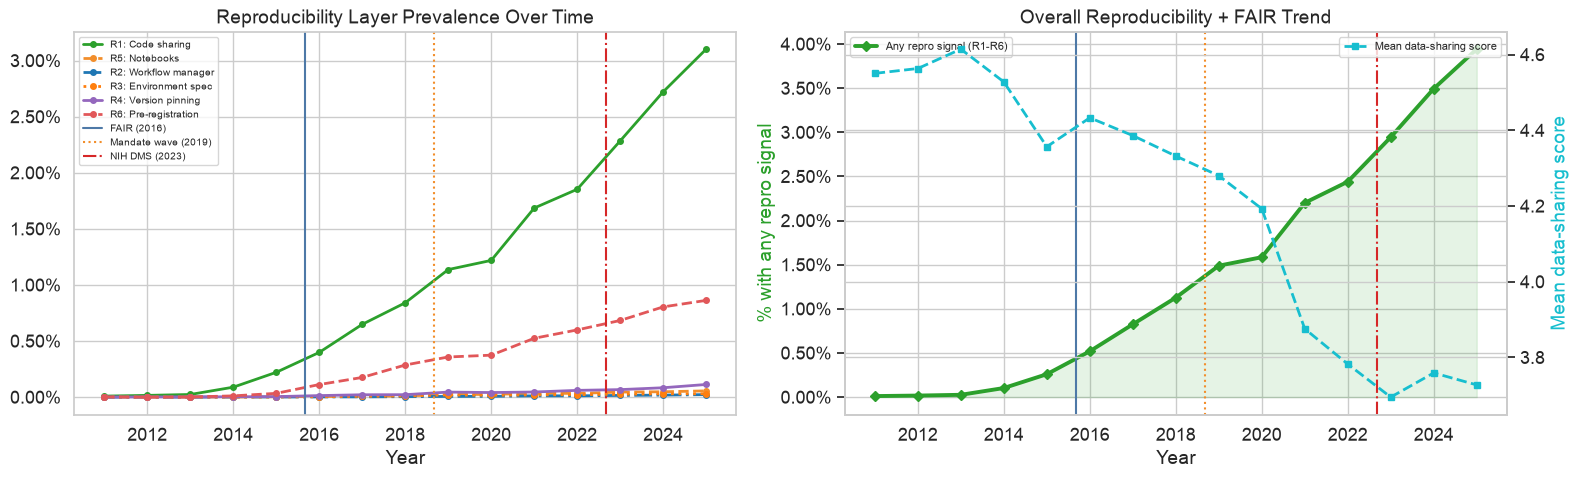

 year  pct_r1  pct_r2  pct_r3  pct_r4  pct_r5  pct_r6  pct_repro  mean_fair
 2011    0.01    0.00    0.00    0.00    0.00    0.00       0.01       4.55
 2012    0.02    0.00    0.00    0.00    0.00    0.00       0.02       4.56
 2013    0.02    0.00    0.00    0.00    0.00    0.00       0.03       4.61
 2014    0.09    0.00    0.00    0.00    0.00    0.01       0.10       4.53
 2015    0.22    0.00    0.00    0.00    0.00    0.03       0.26       4.36
 2016    0.40    0.00    0.00    0.01    0.01    0.11       0.52       4.43
 2017    0.65    0.00    0.01    0.02    0.01    0.18       0.83       4.39
 2018    0.84    0.00    0.01    0.02    0.01    0.29       1.13       4.33
 2019    1.14    0.01    0.02    0.04    0.02    0.36       1.49       4.28
 2020    1.22    0.01    0.02    0.04    0.02    0.37       1.59       4.19
 2021    1.69    0.01    0.02    0.05    0.03    0.52       2.20       3.88
 2022    1.85    0.01    0.02    0.06    0.03    0.60       2.44       3.78
 2023    2.2

In [4]:
yr = df.groupby('year').agg(
    n_total   = ('article_id','count'),
    pct_r1    = ('r1_code',   lambda x: x.mean()*100),
    pct_r2    = ('r2_wf',     lambda x: x.mean()*100),
    pct_r3    = ('r3_env',    lambda x: x.mean()*100),
    pct_r4    = ('r4_ver',    lambda x: x.mean()*100),
    pct_r5    = ('r5_nb',     lambda x: x.mean()*100),
    pct_r6    = ('r6_prereg', lambda x: x.mean()*100),
    pct_repro = ('has_repro', lambda x: x.mean()*100),
    mean_fair = ('data_sharing_score','mean'),
    mean_rs   = ('repro_score','mean'),
).reset_index()
yr = yr[yr['year'].between(2011, 2025)]

MLINES = [
    (FAIR_YEAR    - 0.33, '#4e79a7', '-',  'FAIR (2016)'),
    (MANDATE_YEAR - 0.33, '#f28e2b', ':',  'Mandate wave (2019)'),
    (2023         - 0.33, '#d62728', '-.', 'NIH DMS (2023)'),
]

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
layers = [
    ('pct_r1', C_CODE,   'R1: Code sharing',     '-'),
    ('pct_r5', C_NB,     'R5: Notebooks',         '--'),
    ('pct_r2', C_WF,     'R2: Workflow manager',  '-.'),
    ('pct_r3', C_ENV,    'R3: Environment spec',  ':'),
    ('pct_r4', C_VER,    'R4: Version pinning',   '-'),
    ('pct_r6', C_PREREG, 'R6: Pre-registration',  '--'),
]
for col, clr, lbl, ls in layers:
    ax.plot(yr['year'], yr[col], lw=2.0, marker='o', ms=4,
            color=clr, ls=ls, label=lbl)
for x, c, ls, lbl in MLINES:
    ax.axvline(x, color=c, lw=1.5, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Reproducibility Layer Prevalence Over Time')
ax.set_xlabel('Year'); ax.legend(fontsize=7)

ax = axes[1]
ax.fill_between(yr['year'], yr['pct_repro'], alpha=0.12, color=C_CODE)
ax.plot(yr['year'], yr['pct_repro'], lw=2.8, marker='D', ms=5,
        color=C_CODE, label='Any repro signal (R1-R6)')
ax2r = ax.twinx()
ax2r.plot(yr['year'], yr['mean_fair'], lw=2.0, marker='s', ms=4,
          color=C_FAIR, ls='--', label='Mean data-sharing score')
for x, c, ls, _ in MLINES:
    ax.axvline(x, color=c, lw=1.5, ls=ls)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('% with any repro signal', color=C_CODE)
ax2r.set_ylabel('Mean data-sharing score', color=C_FAIR)
ax.set_title('Overall Reproducibility + FAIR Trend')
ax.set_xlabel('Year')
ax.legend(loc='upper left', fontsize=8)
ax2r.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_repro_01_prevalence.png", **SAVEFIG_KWARGS)
plt.show()
print(yr[['year','pct_r1','pct_r2','pct_r3','pct_r4','pct_r5','pct_r6',
          'pct_repro','mean_fair']].round(2).to_string(index=False))


---
## §2 — Reproducibility × Data-Sharing Score: Correlated or Independent?

FAIR and reproducibility are conceptually related but not identical.
A paper with a FAIR-compliant dataset (named repo, open license, DOI)
but no shared code is FAIR but not reproducible. A paper sharing code
on GitHub with no DAS and no license is reproducible but not FAIR.
We measure their empirical correlation and identify the quadrant structure.

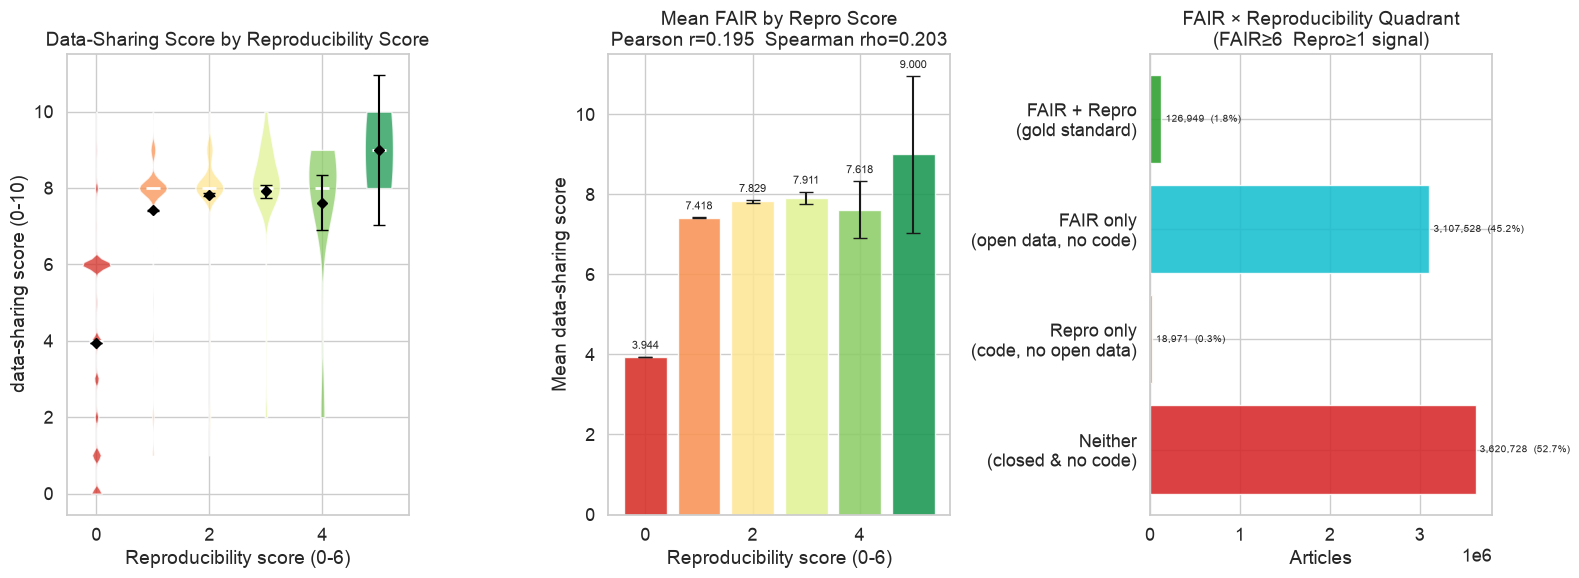

Pearson r  (repro vs FAIR): 0.1945  p=0.00e+00
Spearman rho               : 0.2027  p=0.00e+00


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

# (a) data-sharing score violin by repro score
ax = axes[0]
groups_r = [(s, df[df['repro_score']==s]['data_sharing_score'].dropna())
            for s in range(0, 7)]
valid_r   = [(s, d) for s, d in groups_r if len(d) >= 2]
parts = ax.violinplot([d for _, d in valid_r],
                      positions=[s for s, _ in valid_r],
                      showmedians=True, showextrema=False)
clrs_violin = plt.cm.RdYlGn(np.linspace(0.1, 0.9, len(valid_r)))
for pc, clr in zip(parts['bodies'], clrs_violin):
    pc.set_facecolor(clr); pc.set_alpha(0.75)
parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
for s, d in valid_r:
    ax.errorbar(s, d.mean(), yerr=1.96*d.std()/len(d)**0.5,
                fmt='D', color='black', ms=5, capsize=4, zorder=5)
ax.set_xlabel('Reproducibility score (0-6)')
ax.set_ylabel('data-sharing score (0-10)')
ax.set_title('Data-Sharing Score by Reproducibility Score')

# (b) Mean FAIR per repro score + Pearson r
ax = axes[1]
rs_fair = df.groupby('repro_score')['data_sharing_score'].agg(['mean','std','count'])
clrs_bar = plt.cm.RdYlGn(np.linspace(0.1, 0.9, len(rs_fair)))
bars = ax.bar(rs_fair.index, rs_fair['mean'],
              color=clrs_bar, alpha=0.88, edgecolor='white',
              yerr=1.96*rs_fair['std']/rs_fair['count']**0.5, capsize=5)
ax.bar_label(bars, fmt='{:.3f}', padding=4, fontsize=8)
r_pear, p_pear = stats.pearsonr(df['repro_score'], df['data_sharing_score'].fillna(0))
r_spear, p_sp  = stats.spearmanr(df['repro_score'], df['data_sharing_score'].fillna(0))
ax.set_xlabel('Reproducibility score (0-6)')
ax.set_ylabel('Mean data-sharing score')
ax.set_title(f'Mean FAIR by Repro Score\n'
             f'Pearson r={r_pear:.3f}  Spearman rho={r_spear:.3f}')

# (c) Quadrant: FAIR + Repro classification
ax = axes[2]
fair_thresh  = 6   # FAIR-compliant
repro_thresh = 1   # Any reproducibility signal
quads = {
    'FAIR + Repro\n(gold standard)': ((df['data_sharing_score']>=fair_thresh) & df['has_repro']).sum(),
    'FAIR only\n(open data, no code)': ((df['data_sharing_score']>=fair_thresh) & ~df['has_repro']).sum(),
    'Repro only\n(code, no open data)': ((df['data_sharing_score']<fair_thresh) & df['has_repro']).sum(),
    'Neither\n(closed & no code)': ((df['data_sharing_score']<fair_thresh) & ~df['has_repro']).sum(),
}
qclrs = ['#2ca02c','#17becf','#ff7f0e','#d62728']
bars2 = ax.barh(list(quads)[::-1], list(quads.values())[::-1],
                color=qclrs[::-1], alpha=0.88, edgecolor='white')
ax.bar_label(bars2, labels=[f'{v:,}  ({v/n*100:.1f}%)'
             for v in list(quads.values())[::-1]], padding=3, fontsize=7.5)
ax.set_xlabel('Articles')
ax.set_title('FAIR × Reproducibility Quadrant\n'
             f'(FAIR≥{fair_thresh}  Repro≥{repro_thresh} signal)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_repro_02_correlation.png", **SAVEFIG_KWARGS)
plt.show()
print(f'Pearson r  (repro vs FAIR): {r_pear:.4f}  p={p_pear:.2e}')
print(f'Spearman rho               : {r_spear:.4f}  p={p_sp:.2e}')


---
## §3 — Pre/Post FAIR: Did 2016 Accelerate Reproducibility?

Interrupted time series for the reproducibility score, testing whether
the FAIR principles publication was associated with a structural break
in reproducibility practice adoption — separate from the general
upward trend that preceded it.

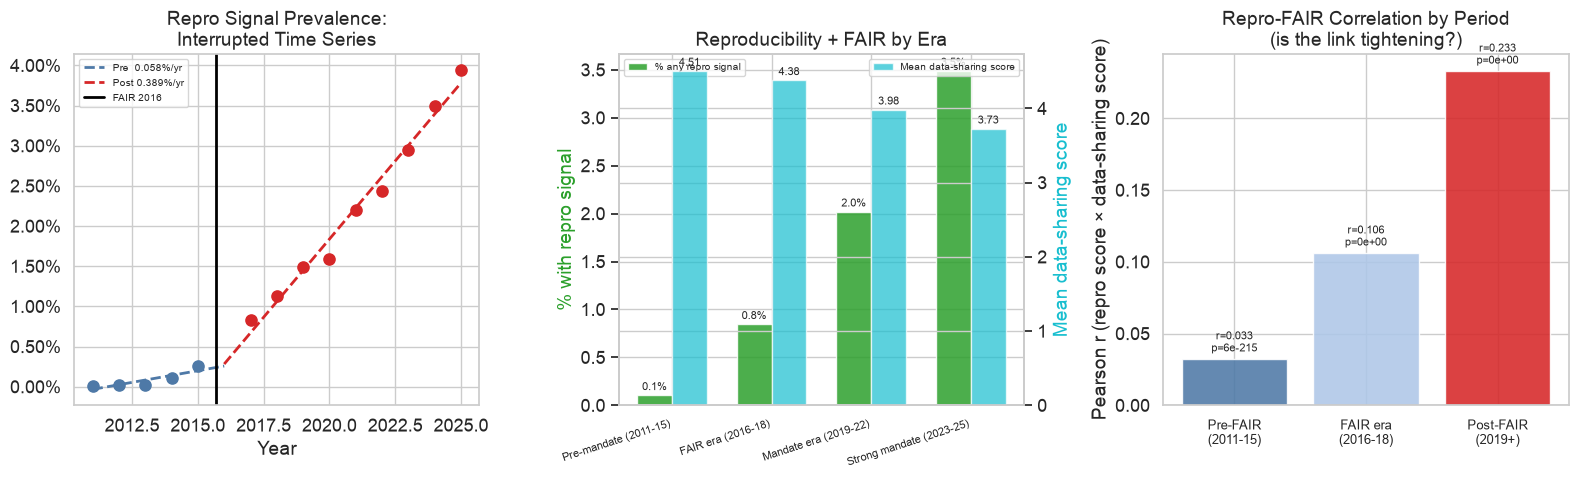

In [6]:
yr_pre  = yr[yr['year'] <  FAIR_YEAR]
yr_post = yr[yr['year'] >  FAIR_YEAR]

def cagr(s):
    v = s.dropna().values
    if len(v) < 2 or v[0] == 0: return float('nan')
    return ((v[-1]/v[0])**(1/(len(v)-1)) - 1)*100

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

# (a) Repro rate ITS
ax = axes[0]
ax.scatter(yr_pre['year'],  yr_pre['pct_repro'],  color=C_PRE,  s=65, zorder=5)
ax.scatter(yr_post['year'], yr_post['pct_repro'], color=C_POST, s=65, zorder=5)
if len(yr_pre) >= 2:
    sl, ic, _, _, _ = stats.linregress(yr_pre['year'], yr_pre['pct_repro'])
    xs = np.linspace(2011, FAIR_YEAR, 40)
    ax.plot(xs, ic+sl*xs, color=C_PRE, lw=2, ls='--',
            label=f'Pre  {sl:.3f}%/yr')
if len(yr_post) >= 2:
    sl2, ic2, _, _, _ = stats.linregress(yr_post['year'], yr_post['pct_repro'])
    xs2 = np.linspace(FAIR_YEAR, 2025, 40)
    ax.plot(xs2, ic2+sl2*xs2, color=C_POST, lw=2, ls='--',
            label=f'Post {sl2:.3f}%/yr')
ax.axvline(FAIR_YEAR-0.33, color='black', lw=2, ls='-', label='FAIR 2016')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Repro Signal Prevalence:\nInterrupted Time Series')
ax.set_xlabel('Year'); ax.legend(fontsize=7.5)

# (b) Era bar: mean repro score + data-sharing score
ax = axes[1]
era_rs = df.groupby('era').agg(
    mean_rs   = ('repro_score','mean'),
    mean_fair = ('data_sharing_score','mean'),
    pct_repro = ('has_repro',  lambda x: x.mean()*100),
).reindex(ERA_ORDER)
x = np.arange(len(ERA_ORDER)); w = 0.35
b1 = ax.bar(x-w/2, era_rs['pct_repro'], width=w, color=C_CODE, alpha=0.85,
            label='% any repro signal', edgecolor='white')
ax.bar_label(b1, fmt='{:.1f}%', padding=2, fontsize=8)
ax2r = ax.twinx()
b2 = ax2r.bar(x+w/2, era_rs['mean_fair'], width=w, color=C_FAIR, alpha=0.70,
              label='Mean data-sharing score', edgecolor='white')
ax2r.bar_label(b2, fmt='{:.2f}', padding=2, fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(ERA_ORDER, rotation=18, ha='right', fontsize=8)
ax.set_ylabel('% with repro signal', color=C_CODE)
ax2r.set_ylabel('Mean data-sharing score', color=C_FAIR)
ax.set_title('Reproducibility + FAIR by Era')
ax.legend(loc='upper left', fontsize=7)
ax2r.legend(loc='upper right', fontsize=7)

# (c) FAIR-Repro gap: how well does data-sharing score predict repro signal?
ax = axes[2]
periods = {
    'Pre-FAIR\n(2011-15)': df[df['year'] < FAIR_YEAR],
    'FAIR era\n(2016-18)': df[(df['year']>=FAIR_YEAR)&(df['year']<=2018)],
    'Post-FAIR\n(2019+)':  df[df['year'] > 2018],
}
for i, (lbl, sub) in enumerate(periods.items()):
    r, p = stats.pearsonr(sub['repro_score'], sub['data_sharing_score'].fillna(0))
    ax.bar(i, r, color=[C_PRE,'#aec7e8',C_POST][i], alpha=0.88, edgecolor='white')
    ax.text(i, r+0.005, f'r={r:.3f}\np={p:.0e}', ha='center', fontsize=8)
ax.set_xticks(range(3)); ax.set_xticklabels(list(periods), fontsize=9)
ax.set_ylabel('Pearson r (repro score × data-sharing score)')
ax.set_title('Repro-FAIR Correlation by Period\n(is the link tightening?)')
ax.axhline(0, color='black', lw=0.8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_repro_03_pre_post_fair.png", **SAVEFIG_KWARGS)
plt.show()


---
## §4 — Reproducibility Score Distribution & Composition

Which combinations of reproducibility layers co-occur? Do papers
that share code also specify environments? Is workflow management
paired with version pinning? We examine the joint distribution
of R1–R6 signals.

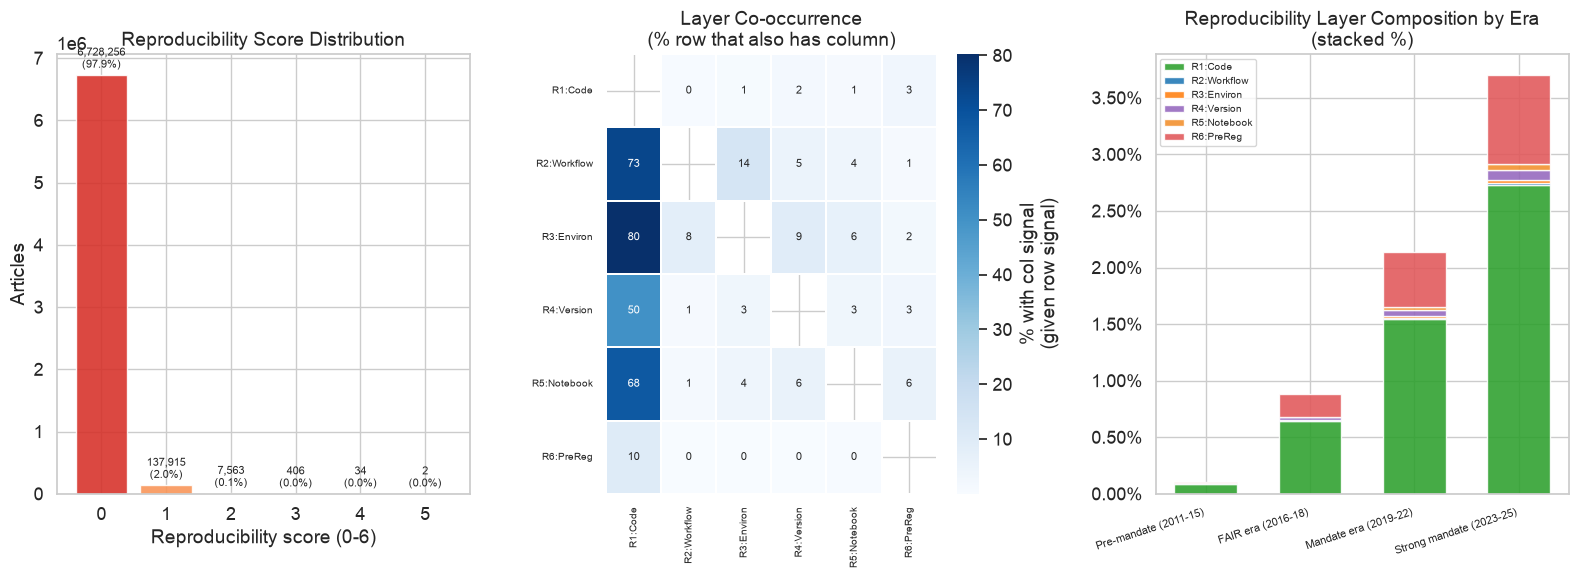

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

# (a) Score distribution histogram
ax = axes[0]
score_vc = df['repro_score'].value_counts().sort_index()
clrs_rs  = plt.cm.RdYlGn(np.linspace(0.1, 0.9, len(score_vc)))
bars = ax.bar(score_vc.index, score_vc.values,
              color=clrs_rs, alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{int(v):,}\n({v/n*100:.1f}%)'
             for v in score_vc.values], padding=3, fontsize=8)
ax.set_xlabel('Reproducibility score (0-6)')
ax.set_ylabel('Articles')
ax.set_title('Reproducibility Score Distribution')

# (b) Layer co-occurrence heatmap
ax = axes[1]
cooc_df = df[REPRO_COLS].copy()
cooc_df.columns = ['R1:Code','R2:Workflow','R3:Environ','R4:Version','R5:Notebook','R6:PreReg']
cooc_mat = pd.DataFrame(index=cooc_df.columns, columns=cooc_df.columns, dtype=float)
for ci in cooc_df.columns:
    for cj in cooc_df.columns:
        cooc_mat.loc[ci, cj] = cooc_df[cooc_df[ci]][cj].mean() * 100
# Set the diagonal via .loc (not np.fill_diagonal(cooc_mat.values, ...)) --
# .values can come back as a non-writable array depending on how pandas
# represents this DataFrame internally; .loc assignment always works.
for _c in cooc_mat.columns:
    cooc_mat.loc[_c, _c] = np.nan
sns.heatmap(cooc_mat.astype(float), annot=True, fmt='.0f', cmap='Blues', ax=ax,
            linewidths=0.3, cbar_kws={'label': '% with col signal\n(given row signal)'},
            annot_kws={'size': 8})
ax.set_title('Layer Co-occurrence\n(% row that also has column)')
ax.tick_params(axis='both', labelsize=7.5)

# (c) Stacked bar by era: repro layer composition
ax = axes[2]
era_layers = df.groupby('era')[REPRO_COLS].mean().reindex(ERA_ORDER) * 100
layer_lbls = ['R1:Code','R2:Workflow','R3:Environ','R4:Version','R5:Notebook','R6:PreReg']
layer_clrs = [C_CODE, C_WF, C_ENV, C_VER, C_NB, C_PREREG]
bot = np.zeros(len(era_layers))
for col, lbl, clr in zip(REPRO_COLS, layer_lbls, layer_clrs):
    vals = era_layers[col].values
    ax.bar(range(len(ERA_ORDER)), vals, bottom=bot,
           color=clr, alpha=0.88, label=lbl, edgecolor='white', width=0.6)
    bot += vals
ax.set_xticks(range(len(ERA_ORDER)))
ax.set_xticklabels(ERA_ORDER, rotation=18, ha='right', fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Reproducibility Layer Composition by Era\n(stacked %)')
ax.legend(fontsize=7, loc='upper left')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_repro_04_score_dist.png", **SAVEFIG_KWARGS)
plt.show()


---
## §5 — Code Sharing Depth: From Scripts to Full Pipelines

R1 (code sharing) is a broad category. We distinguish three levels:
- **Script-level**: any code file mentioned but no workflow tool
- **Notebook-level**: narrated executable document (R5)
- **Pipeline-level**: formal workflow management system (R2)

Higher levels imply greater reproducibility because they make the
execution order and computational environment explicit.

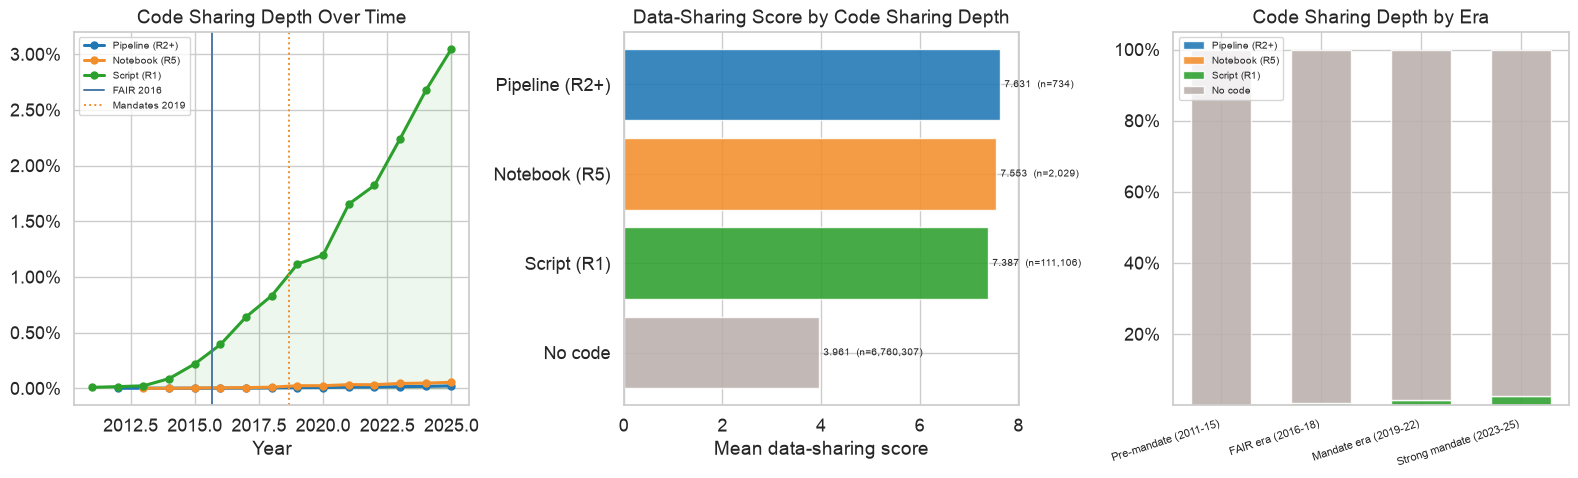

Code depth × data-sharing score:
    code_depth  mean   std   count
Pipeline (R2+) 7.631 1.844     734
 Notebook (R5) 7.553 1.852    2029
   Script (R1) 7.387 2.065  111106
       No code 3.961 2.506 6760307


In [8]:
# Code sharing depth classification
def code_depth(row):
    if row['r2_wf']:   return 'Pipeline (R2+)'
    if row['r5_nb']:   return 'Notebook (R5)'
    if row['r1_code']: return 'Script (R1)'
    return 'No code'
df['code_depth'] = df.apply(code_depth, axis=1)
DEPTH_ORDER = ['Pipeline (R2+)', 'Notebook (R5)', 'Script (R1)', 'No code']
DEPTH_CLRS  = [C_WF, C_NB, C_CODE, '#bab0ac']

yr_depth = (df.groupby(['year','code_depth']).size()
            .reset_index(name='n').merge(yr[['year','n_total']], on='year'))
yr_depth['pct'] = yr_depth['n'] / yr_depth['n_total'] * 100

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
for cd, clr in zip(DEPTH_ORDER[:3], DEPTH_CLRS[:3]):
    sub = yr_depth[yr_depth['code_depth'] == cd]
    ax.fill_between(sub['year'], sub['pct'], alpha=0.08, color=clr)
    ax.plot(sub['year'], sub['pct'], lw=2.2, marker='o', ms=5, color=clr, label=cd)
for x, c, ls, lbl in [(FAIR_YEAR-0.33,'#4e79a7','-','FAIR 2016'),
                       (2019-0.33,'#f28e2b',':','Mandates 2019')]:
    ax.axvline(x, color=c, lw=1.4, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Code Sharing Depth Over Time')
ax.set_xlabel('Year'); ax.legend(fontsize=7.5)

ax = axes[1]
depth_fair = df.groupby('code_depth')['data_sharing_score'].agg(['mean','std','count']).reindex(DEPTH_ORDER).reset_index()
bars = ax.barh(DEPTH_ORDER[::-1], depth_fair['mean'][::-1],
               color=DEPTH_CLRS[::-1], alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{m:.3f}  (n={int(c):,})'
             for m, c in zip(depth_fair['mean'][::-1], depth_fair['count'][::-1])],
             padding=3, fontsize=7.5)
ax.set_xlabel('Mean data-sharing score')
ax.set_title('Data-Sharing Score by Code Sharing Depth')

ax = axes[2]
depth_era = (df.groupby(['era','code_depth']).size()
             .unstack(fill_value=0).reindex(ERA_ORDER)
             .reindex(columns=DEPTH_ORDER, fill_value=0))
depth_pct = depth_era.div(depth_era.sum(axis=1), axis=0) * 100
bot2 = np.zeros(len(depth_pct))
for cd, clr in zip(DEPTH_ORDER, DEPTH_CLRS):
    vals = depth_pct[cd].values
    ax.bar(range(len(ERA_ORDER)), vals, bottom=bot2,
           color=clr, alpha=0.88, label=cd, edgecolor='white', width=0.6)
    bot2 += vals
ax.set_xticks(range(len(ERA_ORDER)))
ax.set_xticklabels(ERA_ORDER, rotation=18, ha='right', fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Code Sharing Depth by Era')
ax.legend(fontsize=7.5, loc='upper left')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_repro_05_code_depth.png", **SAVEFIG_KWARGS)
plt.show()

print('Code depth × data-sharing score:')
print(depth_fair[['code_depth','mean','std','count']].round(3).to_string(index=False))


---
## §6 — Environment Reproducibility: Containers and Version Pinning

The most common failure mode in computational reproducibility is the
**'works on my machine'** problem: code runs with specific library versions
that may not be available or may behave differently later. Docker containers
and Conda environments solve this; explicit version citations help.
We track R3 (environment) and R4 (versioning) adoption and their
co-occurrence with code sharing.

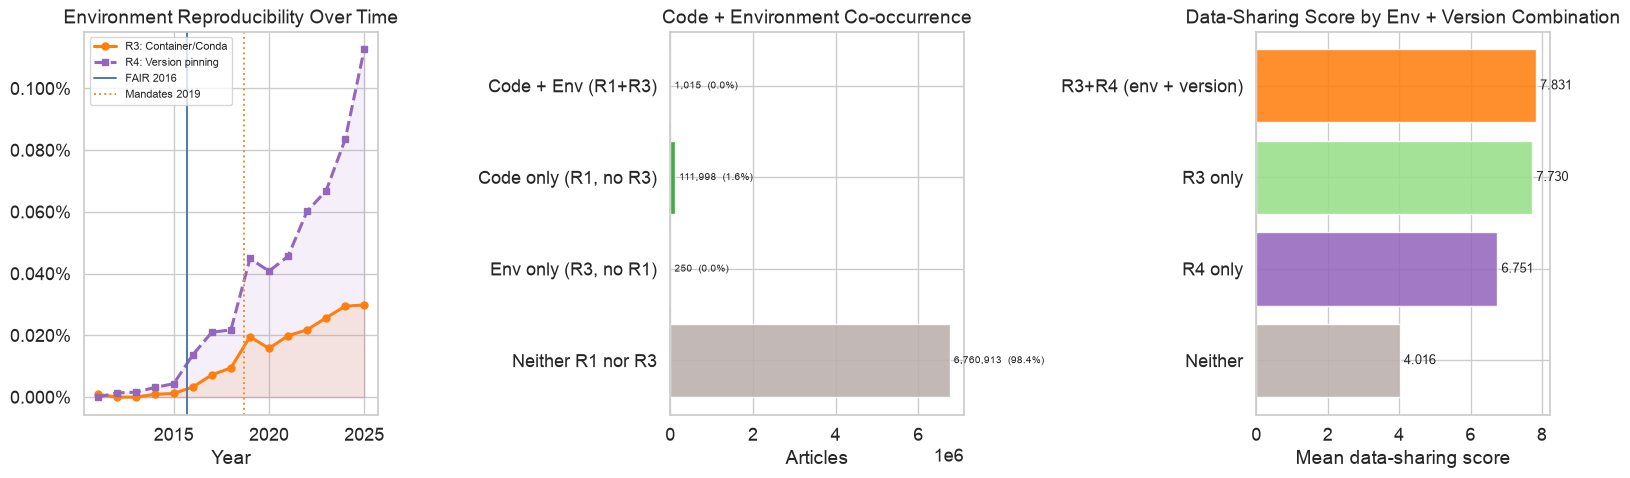

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

# (a) Environment + version trends
ax = axes[0]
ax.fill_between(yr['year'], yr['pct_r3'], alpha=0.10, color=C_ENV)
ax.plot(yr['year'], yr['pct_r3'], lw=2.2, marker='o', ms=5, color=C_ENV,
        label='R3: Container/Conda')
ax.fill_between(yr['year'], yr['pct_r4'], alpha=0.10, color=C_VER)
ax.plot(yr['year'], yr['pct_r4'], lw=2.2, marker='s', ms=5, color=C_VER,
        ls='--', label='R4: Version pinning')
for x, c, ls, lbl in [(FAIR_YEAR-0.33,'#4e79a7','-','FAIR 2016'),
                       (2019-0.33,'#f28e2b',':','Mandates 2019')]:
    ax.axvline(x, color=c, lw=1.4, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Environment Reproducibility Over Time')
ax.set_xlabel('Year'); ax.legend(fontsize=8)

# (b) R3 × R1 co-occurrence: env spec only meaningful with code
ax = axes[1]
env_groups = {
    'Code + Env (R1+R3)':     (df['r1_code'] & df['r3_env']).sum(),
    'Code only (R1, no R3)':  (df['r1_code'] & ~df['r3_env']).sum(),
    'Env only (R3, no R1)':   (~df['r1_code'] & df['r3_env']).sum(),
    'Neither R1 nor R3':      (~df['r1_code'] & ~df['r3_env']).sum(),
}
eg_clrs = [C_ENV, C_CODE, '#ff9896', '#bab0ac']
bars = ax.barh(list(env_groups)[::-1], list(env_groups.values())[::-1],
               color=eg_clrs[::-1], alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{v:,}  ({v/n*100:.1f}%)'
             for v in list(env_groups.values())[::-1]], padding=3, fontsize=7.5)
ax.set_xlabel('Articles')
ax.set_title('Code + Environment Co-occurrence')

# (c) data-sharing score by env+version combination
ax = axes[2]
env_ver_groups = {
    'R3+R4 (env + version)': df[df['r3_env'] & df['r4_ver']]['data_sharing_score'].dropna(),
    'R3 only':                df[df['r3_env'] & ~df['r4_ver']]['data_sharing_score'].dropna(),
    'R4 only':                df[~df['r3_env'] & df['r4_ver']]['data_sharing_score'].dropna(),
    'Neither':                df[~df['r3_env'] & ~df['r4_ver']]['data_sharing_score'].dropna(),
}
valid_ev = [(l, d) for l, d in env_ver_groups.items() if len(d) >= 2]
means_ev  = [d.mean() for _, d in valid_ev]
bars2 = ax.barh([l for l, _ in valid_ev][::-1], means_ev[::-1],
                color=[C_ENV, '#98df8a', C_VER, '#bab0ac'][::-1],
                alpha=0.88, edgecolor='white')
ax.bar_label(bars2, fmt='{:.3f}', padding=3, fontsize=9)
ax.set_xlabel('Mean data-sharing score')
ax.set_title('Data-Sharing Score by Env + Version Combination')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_repro_06_environment.png", **SAVEFIG_KWARGS)
plt.show()


---
## §7 — Reproducibility–Data-Sharing Gap Analysis

We identify four article populations that reveal where the gap between
data-sharing quality and reproducibility is largest:
- **Share+ Repro+**: gold standard (both)
- **Share+ Repro-**: open data but no code — *reusable but not reproducible*
- **Share- Repro+**: code shared but data not high-scoring — *reproducible but not open*
- **Share- Repro-**: neither — most common and most problematic

We track how these four populations have evolved over 15 years.

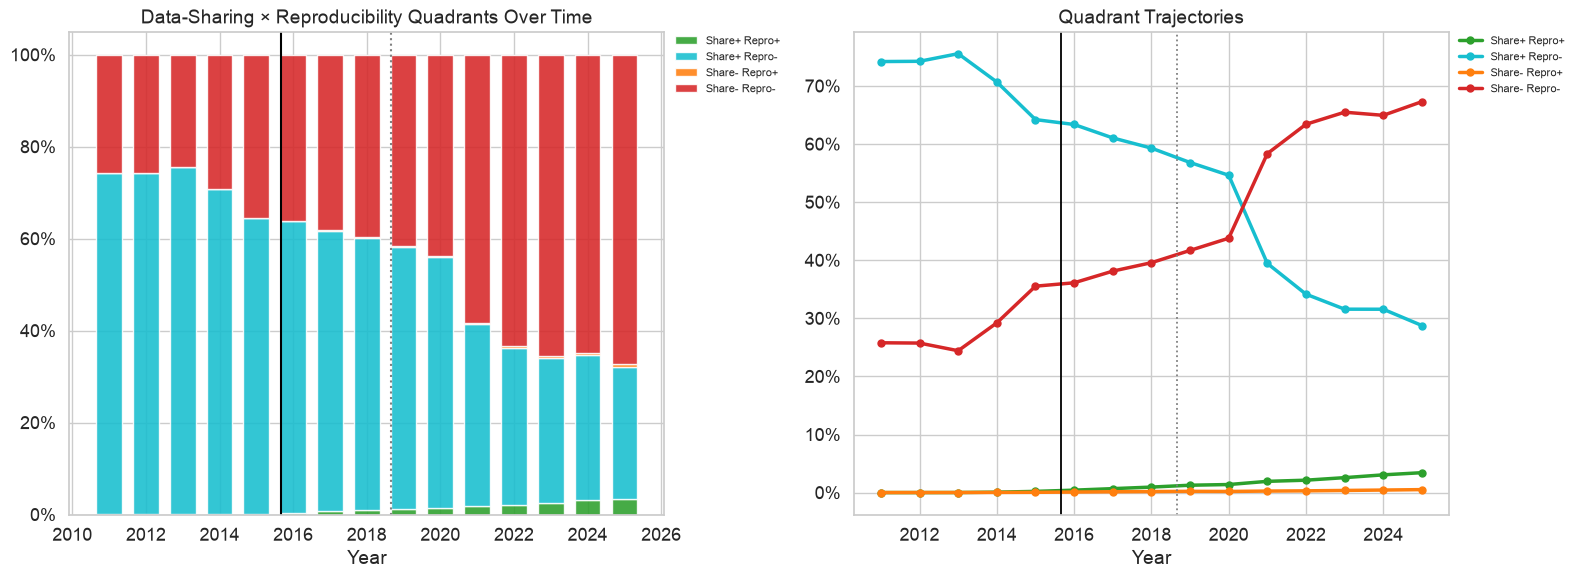

Quadrant sizes:
  Share+ Repro+         126,949  (1.8%)


  Share+ Repro-        3,107,528  (45.2%)
  Share- Repro+          18,971  (0.3%)


  Share- Repro-        3,620,728  (52.7%)

Mean data-sharing score by quadrant:


quadrant
Share+ Repro+    8.174
Share+ Repro-    6.241
Share- Repro+    2.534
Share- Repro-    1.972


In [10]:
df['quadrant'] = 'Share- Repro-'
df.loc[df['data_sharing_score']>=6,  'quadrant'] = 'Share+ Repro-'
df.loc[df['has_repro'],       'quadrant'] = 'Share- Repro+'
df.loc[(df['data_sharing_score']>=6) & df['has_repro'], 'quadrant'] = 'Share+ Repro+'

QUAD_ORDER = ['Share+ Repro+','Share+ Repro-','Share- Repro+','Share- Repro-']
QUAD_CLRS  = ['#2ca02c','#17becf','#ff7f0e','#d62728']

yr_quad = (df.groupby(['year','quadrant']).size()
           .unstack(fill_value=0).reindex(columns=QUAD_ORDER, fill_value=0))
yr_quad_pct = yr_quad.div(yr_quad.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 1))

ax = axes[0]
bot = np.zeros(len(yr_quad_pct))
for q, clr in zip(QUAD_ORDER, QUAD_CLRS):
    vals = yr_quad_pct[q].values
    ax.bar(yr_quad_pct.index, vals, bottom=bot, color=clr, alpha=0.88,
           label=q, edgecolor='white', width=0.7)
    bot += vals
for x, c, ls, lbl in [(FAIR_YEAR-0.33,'black','-','FAIR 2016'),
                       (2019-0.33,'grey',':','Mandates 2019')]:
    ax.axvline(x, color=c, lw=1.5, ls=ls)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Data-Sharing × Reproducibility Quadrants Over Time')
ax.set_xlabel('Year')
# Reviewer feedback: this legend (previously 'lower right') sat on top of
# the stacked quadrant bands in later years. Moved outside the axes so it
# can never occlude the plotted data.
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1.0),
          borderaxespad=0, frameon=False)

ax = axes[1]
# Trajectories
for q, clr in zip(QUAD_ORDER, QUAD_CLRS):
    ax.plot(yr_quad_pct.index, yr_quad_pct[q], lw=2.5, marker='o', ms=5,
            color=clr, label=q)
for x, c, ls, lbl in [(FAIR_YEAR-0.33,'black','-',''),
                       (2019-0.33,'grey',':','')]:
    ax.axvline(x, color=c, lw=1.3, ls=ls)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Quadrant Trajectories')
ax.set_xlabel('Year')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1.0),
          borderaxespad=0, frameon=False)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_repro_07_quadrants.png", **SAVEFIG_KWARGS)
plt.show()

print('Quadrant sizes:')
for q in QUAD_ORDER:
    cnt = (df['quadrant']==q).sum()
    print(f'  {q:20} {cnt:>8,}  ({cnt/n*100:.1f}%)')
print(f'\nMean data-sharing score by quadrant:')
print(df.groupby('quadrant')['data_sharing_score'].mean().reindex(QUAD_ORDER).round(3).to_string())

---
## §8 — Pre-registration and Study Registration Signals

Pre-registration — committing to hypotheses and analysis plan before
data collection — is the strongest guard against p-hacking and HARKing.
OSF, ISRCTN, ClinicalTrials.gov, and PROSPERO are the main registries.
We track R6 (pre-registration) prevalence and its relationship to FAIR.

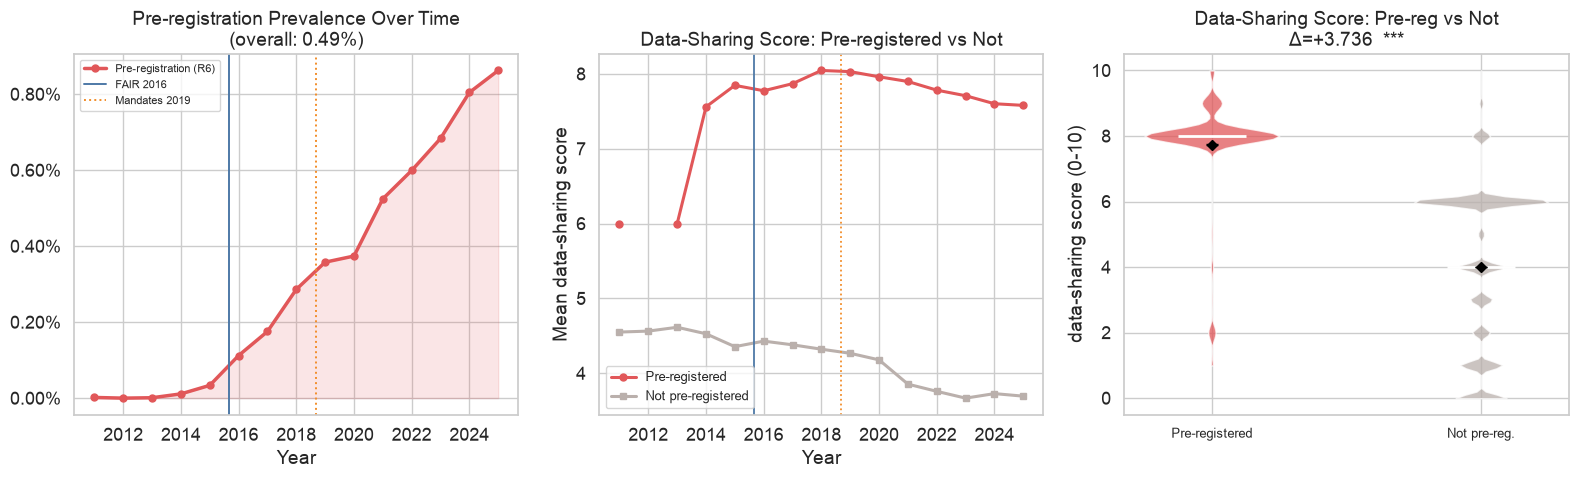

In [11]:
n_prereg = df['r6_prereg'].sum()

yr_prereg = (df.groupby('year').agg(
    pct_prereg = ('r6_prereg', lambda x: x.mean()*100),
    mean_fair_prereg   = ('data_sharing_score', lambda x: x[df.loc[x.index,'r6_prereg']].mean()),
    mean_fair_noprereg = ('data_sharing_score', lambda x: x[~df.loc[x.index,'r6_prereg']].mean()),
).reset_index())
yr_prereg = yr_prereg[yr_prereg['year'].between(2011, 2025)]

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
ax.fill_between(yr_prereg['year'], yr_prereg['pct_prereg'], alpha=0.15, color=C_PREREG)
ax.plot(yr_prereg['year'], yr_prereg['pct_prereg'], lw=2.5, marker='o', ms=5,
        color=C_PREREG, label='Pre-registration (R6)')
for x, c, ls, lbl in [(FAIR_YEAR-0.33,'#4e79a7','-','FAIR 2016'),
                       (2019-0.33,'#f28e2b',':','Mandates 2019')]:
    ax.axvline(x, color=c, lw=1.4, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title(f'Pre-registration Prevalence Over Time\n(overall: {n_prereg/n*100:.2f}%)')
ax.set_xlabel('Year'); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(yr_prereg['year'], yr_prereg['mean_fair_prereg'],   lw=2.2, marker='o', ms=5,
        color=C_PREREG, label='Pre-registered')
ax.plot(yr_prereg['year'], yr_prereg['mean_fair_noprereg'], lw=2.2, marker='s', ms=5,
        color='#bab0ac', label='Not pre-registered')
for x, c, ls in [(FAIR_YEAR-0.33,'#4e79a7','-'),(2019-0.33,'#f28e2b',':')]:
    ax.axvline(x, color=c, lw=1.3, ls=ls)
ax.set_ylabel('Mean data-sharing score')
ax.set_title('Data-Sharing Score: Pre-registered vs Not')
ax.set_xlabel('Year'); ax.legend(fontsize=9)

ax = axes[2]
sc_pr  = df[df['r6_prereg']]['data_sharing_score'].dropna()
sc_npr = df[~df['r6_prereg']]['data_sharing_score'].dropna()
if len(sc_pr) >= 2 and len(sc_npr) >= 2:
    data_prv = [sc_pr, sc_npr]
    parts = ax.violinplot(data_prv, showmedians=True, showextrema=False)
    for pc, c in zip(parts['bodies'], [C_PREREG,'#bab0ac']):
        pc.set_facecolor(c); pc.set_alpha(0.75)
    parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
    for i, d in enumerate(data_prv):
        ax.errorbar(i+1, d.mean(), yerr=1.96*d.std()/len(d)**0.5,
                    fmt='D', color='black', ms=5, capsize=4, zorder=5)
    u, p = stats.mannwhitneyu(sc_pr, sc_npr, alternative='two-sided')
    sig = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else 'ns'
    ax.set_xticks([1,2]); ax.set_xticklabels(['Pre-registered','Not pre-reg.'], fontsize=9)
    ax.set_ylabel('data-sharing score (0-10)')
    ax.set_title(f'Data-Sharing Score: Pre-reg vs Not\nΔ={sc_pr.mean()-sc_npr.mean():+.3f}  {sig}')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_repro_08_prereg.png", **SAVEFIG_KWARGS)
plt.show()


---
## §9 — Discipline-Level Reproducibility Profiles  *(Stage 6)*

Reproducibility norms vary dramatically by field:
bioinformatics and genomics lead with workflow managers and version pinning;
clinical medicine focuses on pre-registration and trial registration;
ecology increasingly uses notebooks and reproducible pipelines.

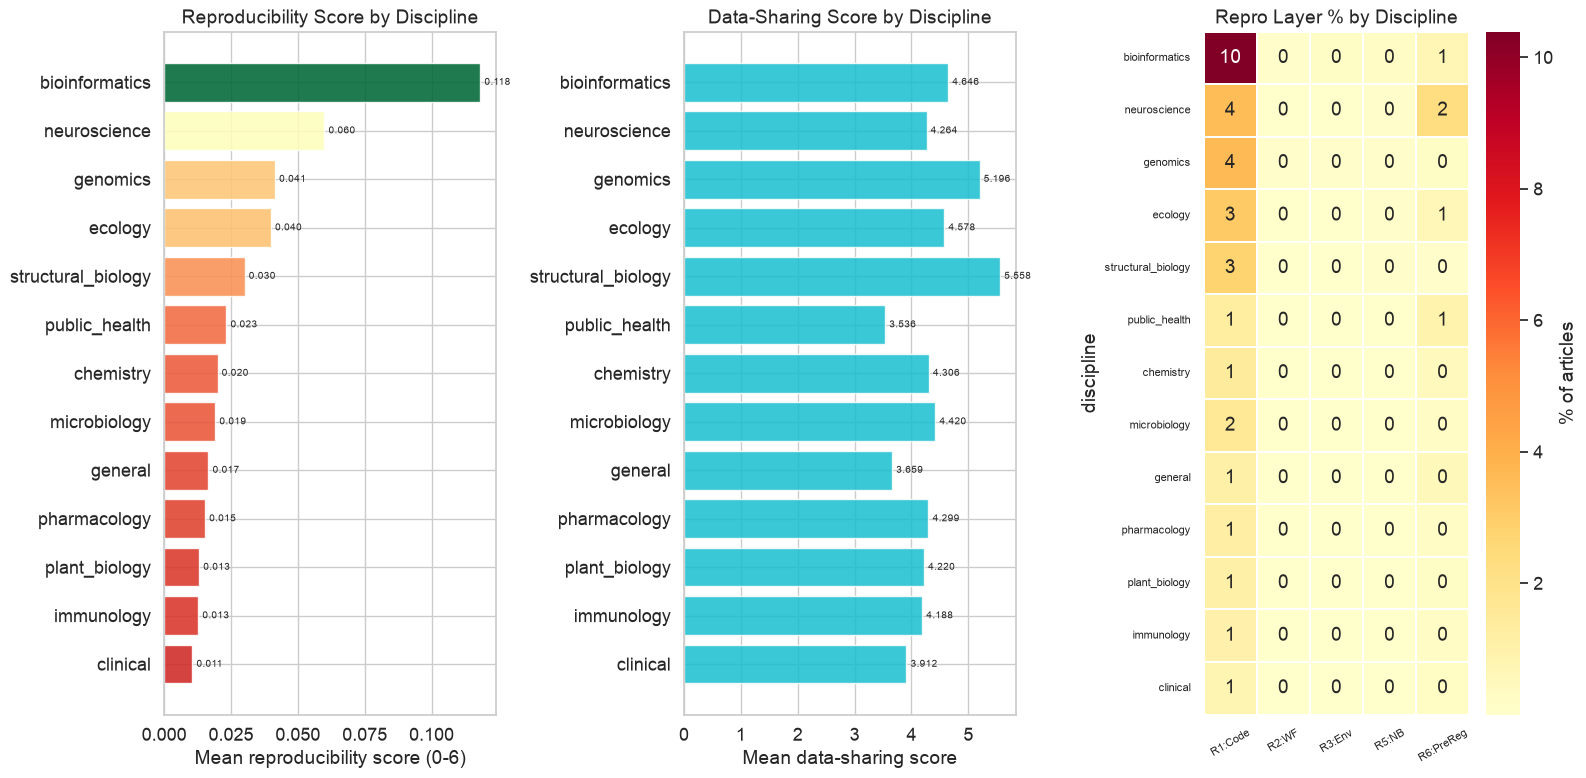

        discipline       n  mean_rs  mean_fair
    bioinformatics  131056    0.118      4.646
      neuroscience  339474    0.060      4.264
          genomics  608274    0.041      5.196
           ecology  157251    0.040      4.578
structural_biology   13630    0.030      5.558
     public_health  245233    0.023      3.536
         chemistry  178242    0.020      4.306
      microbiology  328755    0.019      4.420
           general 2951952    0.017      3.659
      pharmacology  238780    0.015      4.299
     plant_biology  177081    0.013      4.220
        immunology  212017    0.013      4.188
          clinical 1292431    0.011      3.912


In [12]:
if not HAS_DISC:
    print('Skipped — discipline data not available in this database.')
else:
    df_disc = qdb("""SELECT a.article_id, ad.discipline
                  FROM article a JOIN article_discipline ad ON ad.article_id = a.article_id
                  WHERE a.year BETWEEN 2011 AND 2025""")
    df_disc = df_disc.merge(df[['article_id'] + REPRO_COLS +
                                ['repro_score','data_sharing_score','has_repro','quadrant']],
                            on='article_id', how='left')

    disc_agg = df_disc.groupby('discipline').agg(
        n=('article_id','count'),
        mean_rs=('repro_score','mean'),
        mean_fair=('data_sharing_score','mean'),
        pct_r1=('r1_code', lambda x: x.mean()*100),
        pct_r2=('r2_wf',   lambda x: x.mean()*100),
        pct_r3=('r3_env',  lambda x: x.mean()*100),
        pct_r5=('r5_nb',   lambda x: x.mean()*100),
        pct_r6=('r6_prereg',lambda x: x.mean()*100),
    ).reset_index().sort_values('mean_rs', ascending=False)

    fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 3))

    ax = axes[0]
    bars = ax.barh(disc_agg['discipline'][::-1], disc_agg['mean_rs'][::-1],
                   color=plt.cm.RdYlGn(
                       (disc_agg['mean_rs'][::-1] / disc_agg['mean_rs'].max()).values),
                   alpha=0.88, edgecolor='white')
    ax.bar_label(bars, fmt='{:.3f}', padding=3, fontsize=7.5)
    ax.set_xlabel('Mean reproducibility score (0-6)')
    ax.set_title('Reproducibility Score by Discipline')

    ax = axes[1]
    bars2 = ax.barh(disc_agg['discipline'][::-1], disc_agg['mean_fair'][::-1],
                    color='#17becf', alpha=0.85, edgecolor='white')
    ax.bar_label(bars2, fmt='{:.3f}', padding=3, fontsize=7.5)
    ax.set_xlabel('Mean data-sharing score')
    ax.set_title('Data-Sharing Score by Discipline')

    ax = axes[2]
    # Heatmap: discipline × repro layer
    disc_layers = disc_agg.set_index('discipline')[
        ['pct_r1','pct_r2','pct_r3','pct_r5','pct_r6']]
    disc_layers.columns = ['R1:Code','R2:WF','R3:Env','R5:NB','R6:PreReg']
    sns.heatmap(disc_layers, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax,
                linewidths=0.3, cbar_kws={'label': '% of articles'})
    ax.set_title('Repro Layer % by Discipline')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.tick_params(axis='y', rotation=0,  labelsize=8)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_repro_09_discipline.png", **SAVEFIG_KWARGS)
    plt.show()
    print(disc_agg[['discipline','n','mean_rs','mean_fair']].round(3).to_string(index=False))


---
## §10 — Funder × Reproducibility Compliance  *(Stage 6)*

Funders that mandate data sharing may or may not mandate code sharing.
Wellcome Trust and the Gordon & Betty Moore Foundation explicitly require
open code; NIH DMS Policy (2023) requires a software management plan.
We measure whether high-mandate funders produce higher reproducibility scores.

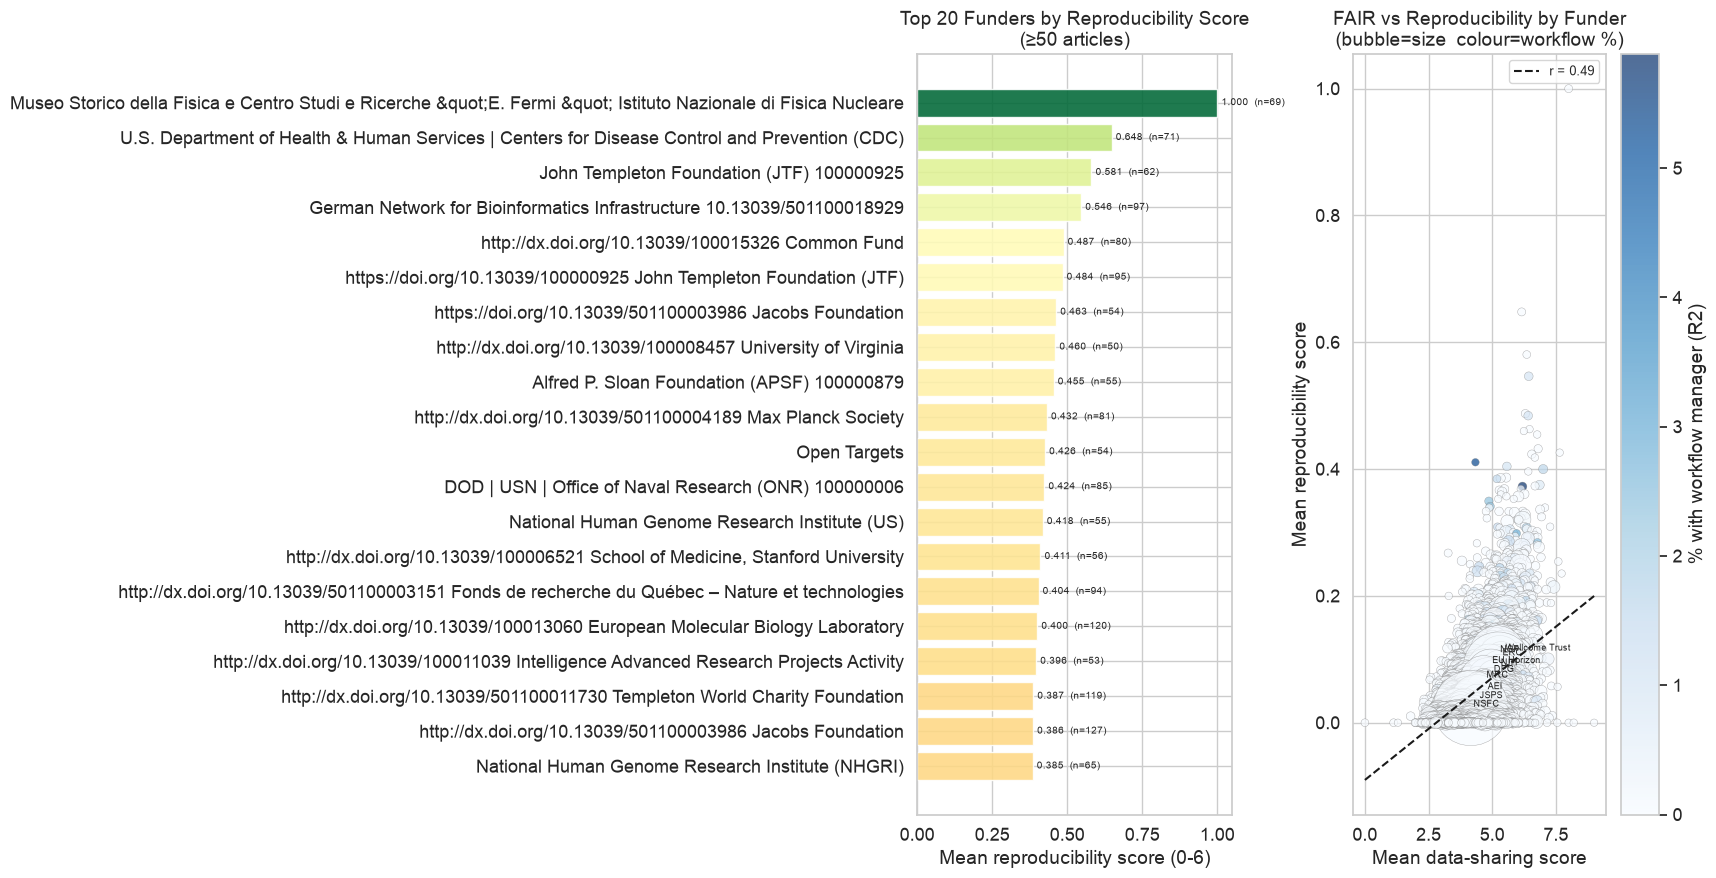

In [13]:
if not HAS_FUNDER:
    print('Skipped — funder data not available in this database.')
else:
    df_af = qdb("""SELECT af.article_id, af.funder_norm AS funder
                 FROM article_funder af JOIN article a ON a.article_id = af.article_id
                 WHERE af.funder_norm != 'none' AND a.year BETWEEN 2011 AND 2025""")
    df_af = df_af.merge(df[['article_id','repro_score','has_repro',
                              'data_sharing_score','r1_code','r2_wf','r5_nb']],
                        on='article_id', how='left')

    f_repro = df_af.groupby('funder').agg(
        n         = ('article_id','count'),
        mean_rs   = ('repro_score','mean'),
        pct_repro = ('has_repro',  lambda x: x.mean()*100),
        pct_r1    = ('r1_code',    lambda x: x.mean()*100),
        pct_r2    = ('r2_wf',      lambda x: x.mean()*100),
        pct_r5    = ('r5_nb',      lambda x: x.mean()*100),
        mean_fair = ('data_sharing_score', 'mean'),
    ).reset_index()
    f_repro_50 = f_repro[f_repro['n'] >= 50].sort_values('mean_rs', ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 3, FIG_H + 4))

    ax = axes[0]
    top20 = f_repro_50.head(20)
    clrs_fr = plt.cm.RdYlGn(
        (top20['mean_rs'] / max(f_repro_50['mean_rs'].max(), 0.01)).values[::-1])
    bars = ax.barh(top20['funder'][::-1], top20['mean_rs'][::-1],
                   color=clrs_fr, alpha=0.88, edgecolor='white')
    ax.bar_label(bars, labels=[f'{r:.3f}  (n={int(n):,})'
                 for r, n in zip(top20['mean_rs'][::-1], top20['n'][::-1])],
                 padding=3, fontsize=7)
    ax.set_xlabel('Mean reproducibility score (0-6)')
    ax.set_title('Top 20 Funders by Reproducibility Score\n(≥50 articles)')

    ax = axes[1]
    sc3 = ax.scatter(f_repro_50['mean_fair'], f_repro_50['mean_rs'],
                     s=np.sqrt(f_repro_50['n'])*4,
                     c=f_repro_50['pct_r2'], cmap='Blues',
                     alpha=0.7, edgecolors='grey', lw=0.3)
    plt.colorbar(sc3, ax=ax, label='% with workflow manager (R2)')
    for _, row in f_repro_50.nlargest(10,'n').iterrows():
        ax.annotate(str(row['funder'])[:16],
                    (row['mean_fair'], row['mean_rs']),
                    fontsize=6.5, xytext=(2,1), textcoords='offset points')
    ax.set_xlabel('Mean data-sharing score')
    ax.set_ylabel('Mean reproducibility score')
    ax.set_title('FAIR vs Reproducibility by Funder\n(bubble=size  colour=workflow %)')
    if len(f_repro_50) >= 5:
        sl, ic, r, _, _ = stats.linregress(f_repro_50['mean_fair'],
                                             f_repro_50['mean_rs'])
        xs = np.linspace(f_repro_50['mean_fair'].min(),
                         f_repro_50['mean_fair'].max(), 50)
        ax.plot(xs, ic+sl*xs, 'k--', lw=1.5, label=f'r = {r:.2f}')
        ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_repro_10_funder.png", **SAVEFIG_KWARGS)
    plt.show()


---
## §11 — Statistical Summary + Exports

In [14]:
print('=' * 72)
print('REPRODUCIBILITY & DATA SHARING  —  STATISTICAL SUMMARY')
print('=' * 72)
for lbl, val in [
        ('Total articles 2011-2025',              f'{n:,}'),
        ('',                                       ''),
        ('R1: Code sharing (any)',                 f'{df["r1_code"].sum():>8,}  ({df["r1_code"].mean()*100:.2f}%)'),
        ('R2: Workflow manager',                   f'{df["r2_wf"].sum():>8,}  ({df["r2_wf"].mean()*100:.2f}%)'),
        ('R3: Environment spec',                   f'{df["r3_env"].sum():>8,}  ({df["r3_env"].mean()*100:.2f}%)'),
        ('R4: Version pinning',                    f'{df["r4_ver"].sum():>8,}  ({df["r4_ver"].mean()*100:.2f}%)'),
        ('R5: Interactive notebooks',              f'{df["r5_nb"].sum():>8,}  ({df["r5_nb"].mean()*100:.2f}%)'),
        ('R6: Pre-registration',                   f'{df["r6_prereg"].sum():>8,}  ({df["r6_prereg"].mean()*100:.2f}%)'),
        ('',                                       ''),
        ('Any repro signal (≥1)',                  f'{df["has_repro"].sum():>8,}  ({df["has_repro"].mean()*100:.1f}%)'),
        ('High repro (≥3)',                         f'{df["high_repro"].sum():>8,}  ({df["high_repro"].mean()*100:.1f}%)'),
        ('Mean repro score (0-6)',                  f'{df["repro_score"].mean():.4f}'),
        ('',                                       ''),
        ('Share+ Repro+ (gold standard)',            f'{(df["quadrant"]=="Share+ Repro+").sum():>8,}  ({(df["quadrant"]=="Share+ Repro+").mean()*100:.1f}%)'),
        ('Share+ Repro- (data, no code)',            f'{(df["quadrant"]=="Share+ Repro-").sum():>8,}  ({(df["quadrant"]=="Share+ Repro-").mean()*100:.1f}%)'),
        ('Share- Repro+ (code, no open data)',       f'{(df["quadrant"]=="Share- Repro+").sum():>8,}  ({(df["quadrant"]=="Share- Repro+").mean()*100:.1f}%)'),
        ('Share- Repro- (neither)',                  f'{(df["quadrant"]=="Share- Repro-").sum():>8,}  ({(df["quadrant"]=="Share- Repro-").mean()*100:.1f}%)'),
        ('',                                       ''),
        ('Pearson r: repro score × data-sharing score',    f'{r_pear:.4f}  (p={p_pear:.2e})'),
]:
    print(f'  {lbl:46} {val}')


REPRODUCIBILITY & DATA SHARING  —  STATISTICAL SUMMARY


  Total articles 2011-2025                       6,874,176
                                                 
  R1: Code sharing (any)                          113,013  (1.64%)
  R2: Workflow manager                                734  (0.01%)
  R3: Environment spec                              1,265  (0.02%)
  R4: Version pinning                               3,638  (0.05%)
  R5: Interactive notebooks                         2,058  (0.03%)
  R6: Pre-registration                             33,697  (0.49%)
                                                 
  Any repro signal (≥1)                           145,920  (2.1%)
  High repro (≥3)                                     442  (0.0%)
  Mean repro score (0-6)                         0.0225
                                                 
  Share+ Repro+ (gold standard)                   126,949  (1.8%)
  Share+ Repro- (data, no code)                  3,107,528  (45.2%)
  Share- Repro+ (code, no open data)               18,971  (0.3%)
 

In [15]:
export_dir = Path('../results/fair_reproducibility_exports')
export_dir.mkdir(parents=True, exist_ok=True)

exports = {
    'article_repro_flags.csv': df[['article_id','year','era'] + REPRO_COLS +
                                   ['repro_score','has_repro','high_repro',
                                    'data_sharing_score','das_cat','quadrant','code_depth']],
    'repro_by_year.csv':       yr[['year','n_total','pct_r1','pct_r2','pct_r3',
                                    'pct_r4','pct_r5','pct_r6','pct_repro','mean_fair']],
    'quadrant_by_year.csv':    yr_quad_pct.reset_index(),
    'code_depth_by_year.csv':  yr_depth,
    'era_repro_summary.csv':   era_rs.reset_index(),
}
if HAS_DISC and 'disc_agg' in dir():
    exports['discipline_repro.csv'] = disc_agg
if HAS_FUNDER and 'f_repro_50' in dir():
    exports['funder_repro.csv'] = f_repro_50

for fname, df_e in exports.items():
    if df_e is None or (hasattr(df_e,'__len__') and len(df_e)==0):
        print(f'  skipped (empty): {fname}'); continue
    df_e.to_csv(export_dir/fname, index=False)
    print(f'  saved  {fname}  ({len(df_e):,} rows)')

con.close()
print('\nAll done.')


  saved  article_repro_flags.csv  (6,874,176 rows)
  saved  repro_by_year.csv  (15 rows)
  saved  quadrant_by_year.csv  (15 rows)
  saved  code_depth_by_year.csv  (56 rows)
  saved  era_repro_summary.csv  (4 rows)
  saved  discipline_repro.csv  (13 rows)
  saved  funder_repro.csv  (8,196 rows)

All done.
